In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

uploaded = files.upload()
file_name = next(iter(uploaded))
df_raw = pd.read_csv(file_name)

print("Raw dataset shape:", df_raw.shape)
display(df_raw.head())

Saving HR_Analytics.csv to HR_Analytics (1).csv
Raw dataset shape: (1480, 38)


,EmpID,Age,AgeGroup,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,SalarySlab,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,RM297,18,18-25,Yes,Travel_Rarely,230,Research & Development,3,3,Life Sciences,1,405,3,Male,54,3,1,Laboratory Technician,3,Single,1420,Upto 5k,25233,1,Y,No,13,3,3,80,0,0,2,3,0,0,0,0.00
1,RM302,18,18-25,No,Travel_Rarely,812,Sales,10,3,Medical,1,411,4,Female,69,2,1,Sales Representative,3,Single,1200,Upto 5k,9724,1,Y,No,12,3,1,80,0,0,2,3,0,0,0,0.00
2,RM458,18,18-25,Yes,Travel_Frequently,1306,Sales,5,3,Marketing,1,614,2,Male,69,3,1,Sales Representative,2,Single,1878,Upto 5k,8059,1,Y,Yes,14,3,4,80,0,0,3,3,0,0,0,0.00
3,RM728,18,18-25,No,Non-Travel,287,Research & Development,5,2,Life Sciences,1,1012,2,Male,73,3,1,Research Scientist,4,Single,1051,Upto 5k,13493,1,Y,No,15,3,4,80,0,0,2,3,0,0,0,0.00
4,RM829,18,18-25,Yes,Non-Travel,247,Research & Development,8,1,Medical,1,1156,3,Male,80,3,1,Laboratory Technician,3,Single,1904,Upto 5k,13556,1,Y,No,12,3,4,80,0,0,0,3,0,0,0,0.00


In [4]:
print("Rows, columns:", df_raw.shape)
print("\\nData types:")
display(df_raw.dtypes.value_counts().rename_axis("Data type").to_frame("Column count"))

print("\\nColumn overview:")
overview = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "non_null": df_raw.notna().sum(),
    "missing": df_raw.isna().sum(),
    "unique": df_raw.nunique(dropna=True)
})
display(overview)

print("\\nAttrition distribution (raw):")
display(df_raw["Attrition"].value_counts(dropna=False).to_frame("Employees"))


Rows, columns: (1480, 38)
\nData types:


,Column count
Data type,
int64,25
object,12
float64,1


\nColumn overview:


,dtype,non_null,missing,unique
EmpID,object,1480,0,1470
Age,int64,1480,0,43
AgeGroup,object,1480,0,5
Attrition,object,1480,0,2
BusinessTravel,object,1480,0,4
DailyRate,int64,1480,0,886
Department,object,1480,0,3
DistanceFromHome,int64,1480,0,29
Education,int64,1480,0,5
EducationField,object,1480,0,6


\nAttrition distribution (raw):


,Employees
Attrition,
No,1242
Yes,238


In [5]:
print("Exact duplicate rows:", df_raw.duplicated().sum())
print("Missing values by column:")
display(df_raw.isna().sum().sort_values(ascending=False).loc[lambda s: s > 0].to_frame("Missing"))

print("Duplicated EmpID rows:")
dup_ids = df_raw[df_raw.duplicated("EmpID", keep=False)].sort_values("EmpID")
display(dup_ids[["EmpID", "Attrition", "YearsWithCurrManager", "Age", "Department", "JobRole"]])

for col in df_raw.select_dtypes(include="object").columns:
    print(f"\\n{col}:")
    print(sorted(df_raw[col].dropna().astype(str).unique().tolist())[:30])


Exact duplicate rows: 7
Missing values by column:


,Missing
YearsWithCurrManager,57


Duplicated EmpID rows:


,EmpID,Attrition,YearsWithCurrManager,Age,Department,JobRole
327,RM1461,No,4.00,29,Research & Development,Research Scientist
328,RM1461,No,4.00,29,Research & Development,Research Scientist
1336,RM1462,Yes,0.00,50,Sales,Sales Executive
1335,RM1462,Yes,0.00,50,Sales,Sales Executive
954,RM1463,No,6.00,39,Sales,Sales Executive
952,RM1463,No,6.00,39,Sales,Sales Executive
457,RM1464,No,7.00,31,Research & Development,Manufacturing Director
458,RM1464,No,7.00,31,Research & Development,Manufacturing Director
161,RM1465,No,0.00,26,Sales,Sales Representative
162,RM1465,No,5.00,26,Sales,Sales Representative


\nEmpID:
['RM001', 'RM002', 'RM003', 'RM004', 'RM005', 'RM006', 'RM007', 'RM008', 'RM009', 'RM010', 'RM011', 'RM012', 'RM013', 'RM014', 'RM015', 'RM016', 'RM017', 'RM018', 'RM019', 'RM020', 'RM021', 'RM022', 'RM023', 'RM024', 'RM025', 'RM026', 'RM027', 'RM028', 'RM029', 'RM030']
\nAgeGroup:
['18-25', '26-35', '36-45', '46-55', '55+']
\nAttrition:
['No', 'Yes']
\nBusinessTravel:
['Non-Travel', 'TravelRarely', 'Travel_Frequently', 'Travel_Rarely']
\nDepartment:
['Human Resources', 'Research & Development', 'Sales']
\nEducationField:
['Human Resources', 'Life Sciences', 'Marketing', 'Medical', 'Other', 'Technical Degree']
\nGender:
['Female', 'Male']
\nJobRole:
['Healthcare Representative', 'Human Resources', 'Laboratory Technician', 'Manager', 'Manufacturing Director', 'Research Director', 'Research Scientist', 'Sales Executive', 'Sales Representative']
\nMaritalStatus:
['Divorced', 'Married', 'Single']
\nSalarySlab:
['10k-15k', '15k+', '5k-10k', 'Upto 5k']
\nOver18:
['Y']
\nOverTime:
['

In [6]:
df = df_raw.drop_duplicates().copy()

# Pastikan setiap EmpID hanya dihitung satu kali.
# Untuk ID yang memiliki konflik YearsWithCurrManager, tandai nilai tersebut sebagai missing.
conflicting_ids = (
    df.groupby("EmpID")["YearsWithCurrManager"]
      .nunique(dropna=False)
      .loc[lambda s: s > 1]
      .index
      .tolist()
)

df = df.sort_values("EmpID").drop_duplicates("EmpID", keep="first").copy()
df.loc[df["EmpID"].isin(conflicting_ids), "YearsWithCurrManager"] = np.nan

# Standardisasi kategori BusinessTravel
df["BusinessTravel"] = (
    df["BusinessTravel"].astype("string").str.strip()
      .replace({
          "TravelRarely": "Travel_Rarely",
          "Travel_Frequently": "Travel_Frequently",
          "Non-Travel": "Non-Travel"
      })
)

# Pastikan kategori target konsisten
df["Attrition"] = df["Attrition"].astype("string").str.strip().str.title()

constant_or_noninformative = ["EmployeeCount", "Over18", "StandardHours"]
df = df.drop(columns=[c for c in constant_or_noninformative if c in df.columns])

print("Shape after cleaning:", df.shape)
print("Unique EmpID:", df["EmpID"].nunique())
print("Conflicting IDs:", conflicting_ids)
print("Remaining missing values:")
display(df.isna().sum().loc[lambda s: s > 0].to_frame("Missing"))
print("Duplicate EmpID after cleaning:", df["EmpID"].duplicated().sum())


Shape after cleaning: (1470, 35)
Unique EmpID: 1470
Conflicting IDs: ['RM1465', 'RM1466', 'RM1467']
Remaining missing values:


,Missing
YearsWithCurrManager,60


Duplicate EmpID after cleaning: 0


In [7]:
total_employees = df["EmpID"].nunique()
attrition_count = (df["Attrition"] == "Yes").sum()
active_count = (df["Attrition"] == "No").sum()
attrition_rate = attrition_count / total_employees * 100
avg_age = df["Age"].mean()
avg_income = df["MonthlyIncome"].mean()

kpi = pd.DataFrame({
    "Metric": ["Total Employees", "Active Employees", "Attrition Count",
               "Attrition Rate (%)", "Average Age", "Average Monthly Income"],
    "Value": [total_employees, active_count, attrition_count,
              attrition_rate, avg_age, avg_income]
})
display(kpi)


,Metric,Value
0,Total Employees,"1,470.00"
1,Active Employees,"1,233.00"
2,Attrition Count,237.00
3,Attrition Rate (%),16.12
4,Average Age,36.92
5,Average Monthly Income,"6,502.93"


,Employees
Attrition,
Active,1233
Left,237


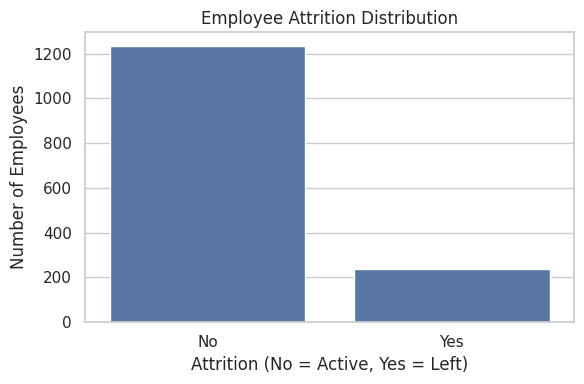

In [8]:
attrition_counts = df["Attrition"].value_counts().reindex(["No", "Yes"])
display(attrition_counts.rename(index={"No": "Active", "Yes": "Left"}).to_frame("Employees"))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Attrition", order=["No", "Yes"])
plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition (No = Active, Yes = Left)")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()


\nAttrition by AgeGroup


,Total_Employees,Attrition_Count,Attrition_Rate_pct
AgeGroup,,,
18-25,123,44,35.77
26-35,606,116,19.14
55+,47,8,17.02
46-55,226,26,11.50
36-45,468,43,9.19


\nAttrition by Gender


,Total_Employees,Attrition_Count,Attrition_Rate_pct
Gender,,,
Male,882,150,17.01
Female,588,87,14.80


\nAttrition by MaritalStatus


,Total_Employees,Attrition_Count,Attrition_Rate_pct
MaritalStatus,,,
Single,470,120,25.53
Married,673,84,12.48
Divorced,327,33,10.09


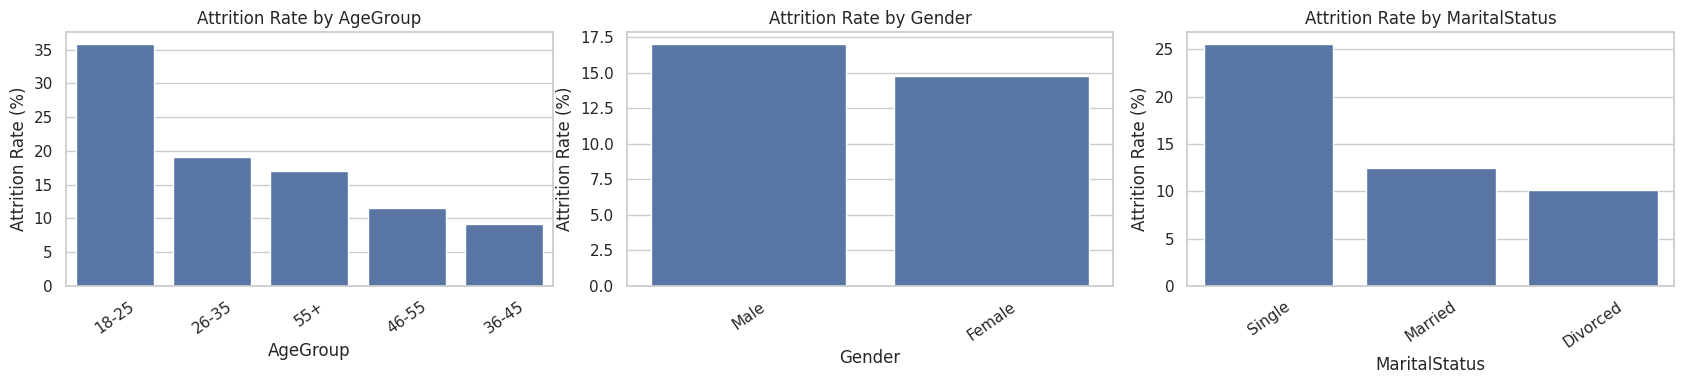

In [9]:
def attrition_by_group(data, group_col):
    result = data.groupby(group_col, dropna=False).agg(
        Total_Employees=("EmpID", "nunique"),
        Attrition_Count=("Attrition", lambda x: (x == "Yes").sum())
    )
    result["Attrition_Rate_pct"] = (
        result["Attrition_Count"] / result["Total_Employees"] * 100
    )
    return result.sort_values("Attrition_Rate_pct", ascending=False)

# AgeGroup tersedia pada dataset; gunakan kategori yang disediakan.
for col in ["AgeGroup", "Gender", "MaritalStatus"]:
    print(f"\\nAttrition by {col}")
    display(attrition_by_group(df, col))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col in zip(axes, ["AgeGroup", "Gender", "MaritalStatus"]):
    tmp = attrition_by_group(df, col).sort_values("Attrition_Rate_pct", ascending=False)
    sns.barplot(data=tmp.reset_index(), x=col, y="Attrition_Rate_pct", ax=ax)
    ax.set_title(f"Attrition Rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Attrition Rate (%)")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()


\nAttrition by Department


,Total_Employees,Attrition_Count,Attrition_Rate_pct
Department,,,
Sales,446,92,20.63
Human Resources,63,12,19.05
Research & Development,961,133,13.84


\nAttrition by JobRole


,Total_Employees,Attrition_Count,Attrition_Rate_pct
JobRole,,,
Sales Representative,83,33,39.76
Laboratory Technician,259,62,23.94
Human Resources,52,12,23.08
Sales Executive,326,57,17.48
Research Scientist,292,47,16.10
Manufacturing Director,145,10,6.90
Healthcare Representative,131,9,6.87
Manager,102,5,4.90
Research Director,80,2,2.50


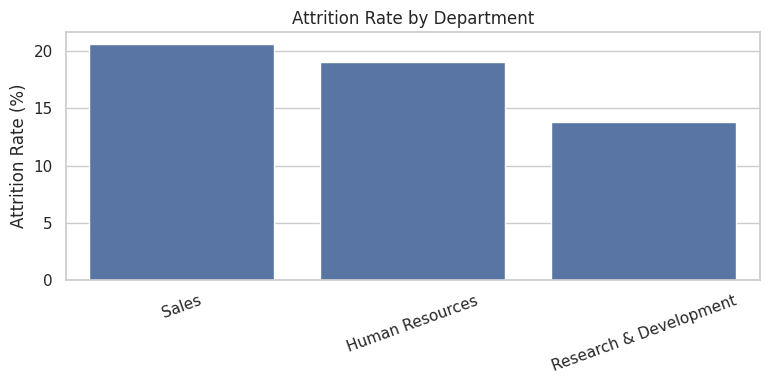

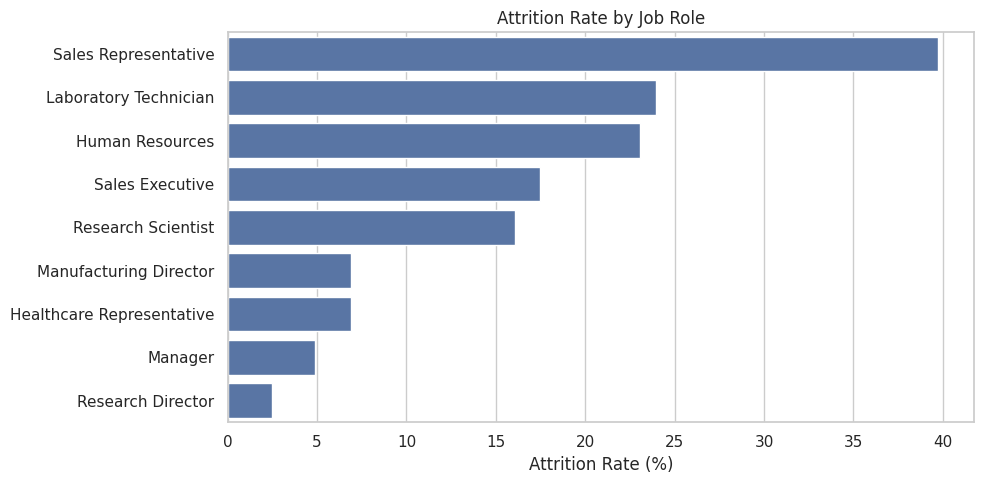

In [10]:
for col in ["Department", "JobRole"]:
    print(f"\\nAttrition by {col}")
    display(attrition_by_group(df, col))

dept = attrition_by_group(df, "Department").reset_index()
plt.figure(figsize=(8, 4))
sns.barplot(data=dept, x="Department", y="Attrition_Rate_pct")
plt.title("Attrition Rate by Department")
plt.ylabel("Attrition Rate (%)")
plt.xlabel("")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

role = attrition_by_group(df, "JobRole").reset_index()
plt.figure(figsize=(10, 5))
sns.barplot(data=role, y="JobRole", x="Attrition_Rate_pct")
plt.title("Attrition Rate by Job Role")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()


\nAttrition by SalarySlab


,Total_Employees,Attrition_Count,Attrition_Rate_pct
SalarySlab,,,
Upto 5k,749,163,21.76
10k-15k,148,20,13.51
5k-10k,440,49,11.14
15k+,133,5,3.76


\nAttrition by JobLevel


,Total_Employees,Attrition_Count,Attrition_Rate_pct
JobLevel,,,
1,543,143,26.34
3,218,32,14.68
2,534,52,9.74
5,69,5,7.25
4,106,5,4.72


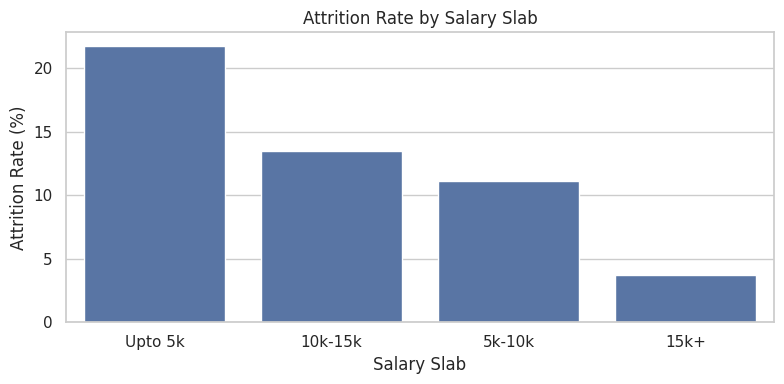

In [11]:
for col in ["SalarySlab", "JobLevel"]:
  print(f"\\nAttrition by {col}")
  display(attrition_by_group(df, col))

salary = attrition_by_group(df,"SalarySlab").reset_index()
plt.figure(figsize=(8,4))
sns.barplot(data=salary, x="SalarySlab", y="Attrition_Rate_pct")
plt.title("Attrition Rate by Salary Slab")
plt.ylabel("Attrition Rate (%)")
plt.xlabel("Salary Slab")
plt.tight_layout()
plt.show()


\nAttrition by JobSatisfaction


,Total_Employees,Attrition_Count,Attrition_Rate_pct
JobSatisfaction,,,
1,289,66,22.84
3,442,73,16.52
2,280,46,16.43
4,459,52,11.33


\nAttrition by EnvironmentSatisfaction


,Total_Employees,Attrition_Count,Attrition_Rate_pct
EnvironmentSatisfaction,,,
1,284,72,25.35
2,287,43,14.98
3,453,62,13.69
4,446,60,13.45


\nAttrition by RelationshipSatisfaction


,Total_Employees,Attrition_Count,Attrition_Rate_pct
RelationshipSatisfaction,,,
1,276,57,20.65
3,459,71,15.47
2,303,45,14.85
4,432,64,14.81


\nAttrition by WorkLifeBalance


,Total_Employees,Attrition_Count,Attrition_Rate_pct
WorkLifeBalance,,,
1,80,25,31.25
4,153,27,17.65
2,344,58,16.86
3,893,127,14.22


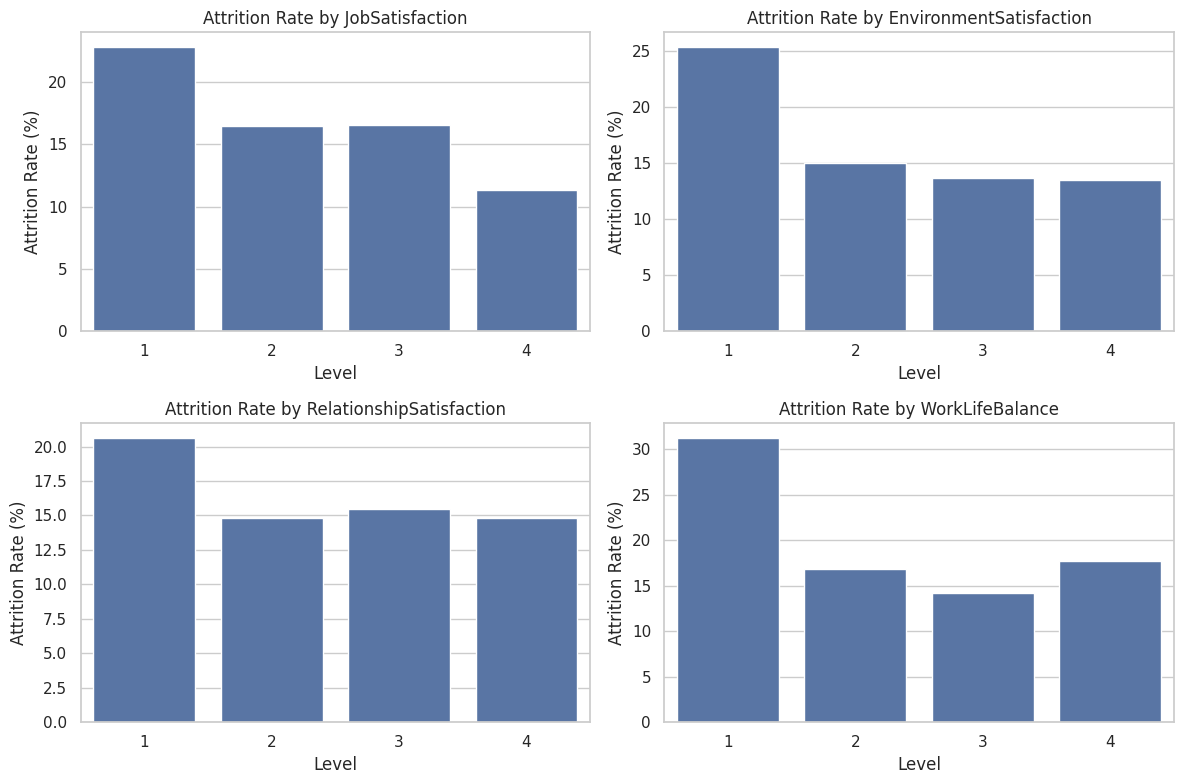

In [12]:
satisfaction_cols = [
    "JobSatisfaction",
    "EnvironmentSatisfaction",
    "RelationshipSatisfaction",
    "WorkLifeBalance"
]

for col in satisfaction_cols:
    print(f"\\nAttrition by {col}")
    display(attrition_by_group(df, col))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flatten(), satisfaction_cols):
    tmp = attrition_by_group(df, col).reset_index().sort_values(col)
    sns.barplot(data=tmp, x=col, y="Attrition_Rate_pct", ax=ax)
    ax.set_title(f"Attrition Rate by {col}")
    ax.set_xlabel("Level")
    ax.set_ylabel("Attrition Rate (%)")
plt.tight_layout()
plt.show()


Attrition,No,Yes
TotalWorkingYears,11.86,8.24
YearsAtCompany,7.37,5.13
YearsInCurrentRole,4.48,2.90
YearsSinceLastPromotion,2.23,1.95


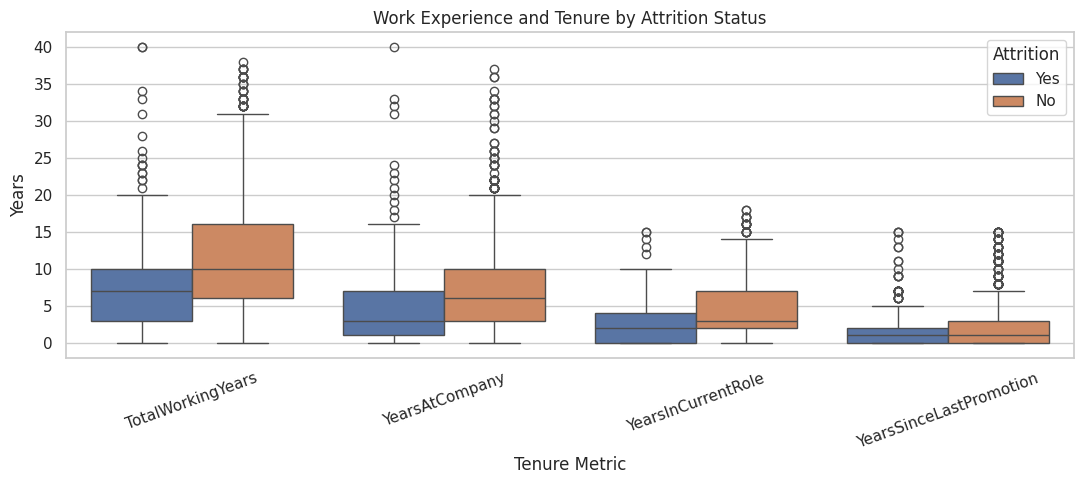

In [13]:
tenure_cols = [
    "TotalWorkingYears", "YearsAtCompany",
    "YearsInCurrentRole", "YearsSinceLastPromotion"
]

tenure_summary = df.groupby("Attrition")[tenure_cols].mean().T
display(tenure_summary)

tenure_long = df.melt(
    id_vars="Attrition",
    value_vars=tenure_cols,
    var_name="Tenure Metric",
    value_name="Years"
)
plt.figure(figsize=(11, 5))
sns.boxplot(data=tenure_long, x="Tenure Metric", y="Years", hue="Attrition")
plt.title("Work Experience and Tenure by Attrition Status")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


,JobRole,Total_Employees,Attrition_Count,Attrition_Rate_pct
1,Laboratory Technician,259,62,23.94
3,Sales Executive,326,57,17.48
4,Research Scientist,292,47,16.10
0,Sales Representative,83,33,39.76
2,Human Resources,52,12,23.08
5,Manufacturing Director,145,10,6.90
6,Healthcare Representative,131,9,6.87
7,Manager,102,5,4.90
8,Research Director,80,2,2.50


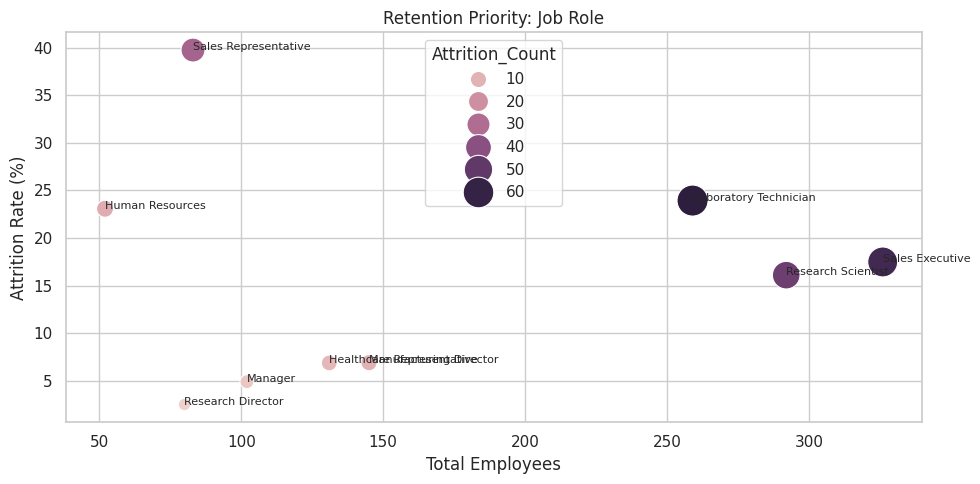

In [14]:
priority = attrition_by_group(df, "JobRole").reset_index()
priority = priority.sort_values(
    ["Attrition_Count", "Attrition_Rate_pct"],
    ascending=False
)
display(priority)

plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=priority,
    x="Total_Employees",
    y="Attrition_Rate_pct",
    size="Attrition_Count",
    sizes=(80, 500),
    hue="Attrition_Count",
    legend=True
)
for _, row in priority.iterrows():
    plt.text(row["Total_Employees"], row["Attrition_Rate_pct"],
             str(row["JobRole"]), fontsize=8)
plt.title("Retention Priority: Job Role")
plt.xlabel("Total Employees")
plt.ylabel("Attrition Rate (%)")
plt.tight_layout()
plt.show()


In [15]:
output_file = "HR_Analytics_Cleaned.csv"
df.to_csv(output_file, index=False)
print("Saved:", output_file)

# Download dari Google Colab
files.download(output_file)


Saved: HR_Analytics_Cleaned.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>